# Machine Translation: French ➜ English (and How to Judge the AI)

In this notebook the computer will **translate French sentences into English**.
Then we will ask the hardest question of the course: **how do you score a translation, when many answers can be right?**

**Part 1: Live demo**
- type **any French sentence** and compare a **small** and a **big** translation model
- try idioms: *"Il pleut des cordes"*, *"Je suis tombé dans les pommes"*...

**Part 2: Evaluation**
- **BLEU, step by step**, with colors: which words match?
- **chrF** and **TER**, and a full test on 18 sentences (daily life, news, idioms, medicine, tech)
- the **dangerous trap**: BLEU prefers a translation with the **opposite meaning**
- why **several references** change everything
- an **ethics test**: does the model turn *"the doctor... she"* into a man?

## What is machine translation?

Imagine an interpreter who **listens to the whole French sentence**, then **writes the English sentence word by word**,
looking back at the French each time. That is the **encoder-decoder Transformer** of slide 25.

| | Classification (01) | Sequence labeling (02) | **Translation (03)** |
|---|---|---|---|
| Output | 1 label | 1 label per word | **a whole new sentence** |
| Number of correct answers | 1 | 1 per word | **many!** |

## Step 0: Prepare your computer (one time only)

```bash
python -m venv .venv
source .venv/bin/activate            # Windows: .venv\Scripts\Activate.ps1
pip install ipykernel transformers torch sentencepiece sacremoses sacrebleu matplotlib pandas
```

Then in VS Code: **Select Kernel** > **Python Environments** > **.venv**. The cell below does the install for you.

In [ ]:
%pip install -q transformers torch sentencepiece sacremoses sacrebleu matplotlib pandas

## Step 1: Import the tools

- `transformers`: the **MarianMT** translation models (trained on millions of real translated sentences, the OPUS corpus)
- `sacrebleu`: the **official** tool to compute BLEU, chrF and TER (everybody uses it, so scores are comparable)
- `pandas`, `matplotlib`, `IPython.display`: tables, charts and colored text

In [8]:
import re
import time
import warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import sacrebleu
from transformers import pipeline

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, PINK, YELLOW, GREEN, RED = "#0090ea", "#eb04a3", "#fdcb58", "#21b35a", "#d62828"
print("All tools loaded. sacrebleu version:", sacrebleu.__version__)

All tools loaded. sacrebleu version: 2.6.0


In [6]:
SMALL_MODEL   = "Helsinki-NLP/opus-mt-fr-en"
BIG_MODEL     = "Helsinki-NLP/opus-mt-tc-big-fr-en"
EN_FR_MODEL   = "Helsinki-NLP/opus-mt-en-fr"
RUN_BIG_MODEL = True
NUM_BEAMS     = 4
USE_COMET     = False
LIVE_DEMO     = True

## Step 3: Load the models

Both are **MarianMT** models: an encoder reads the French sentence, a decoder writes the English one (slide 25).
They differ only in **size** and **training data**.

In [9]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM


class Translator:
    # Loads a MarianMT model and translates (replaces pipeline("translation"), removed in transformers v5)
    def __init__(self, model_name):
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(model_name).eval()

    def __call__(self, texts, batch_size=8, num_beams=4, max_length=256, **kwargs):
        texts = [texts] if isinstance(texts, str) else list(texts)
        results = []
        for i in range(0, len(texts), batch_size):
            batch = self.tokenizer(texts[i:i + batch_size], return_tensors="pt", padding=True, truncation=True)
            with torch.no_grad():
                generated = self.model.generate(**batch, num_beams=num_beams, max_new_tokens=max_length)
            results += [{"translation_text": t} for t in self.tokenizer.batch_decode(generated, skip_special_tokens=True)]
        return results


MODELS = {"small": Translator(SMALL_MODEL)}
if RUN_BIG_MODEL:
    MODELS["big"] = Translator(BIG_MODEL)

PARAMS = {name: m.model.num_parameters() / 1e6 for name, m in MODELS.items()}
for name, p in PARAMS.items():
    print(f"{name:>5} model: {p:.0f} million parameters")


def translate(texts, name="small"):
    single = isinstance(texts, str)
    texts = [texts] if single else list(texts)
    out = MODELS[name](texts, batch_size=8, num_beams=NUM_BEAMS, max_length=256)
    res = [o["translation_text"] for o in out]
    return res[0] if single else res

Loading weights: 100%|██████████| 254/254 [00:00<00:00, 4048.94it/s]


small model: 75 million parameters
  big model: 233 million parameters


## Step 4: What happens inside, in one picture

```
 FRENCH  "Le chat dort"
    |
 ENCODER  reads the whole sentence (self-attention: every word looks at every word)
    |
 DECODER  writes one English word at a time, looking back at the French (cross-attention)
    |        <start> -> The -> cat -> sleeps -> <end>
    v
 ENGLISH "The cat sleeps"
```

**Beam search** (`NUM_BEAMS = 4`): instead of keeping only the best word at each step, the model keeps the **4 best beginnings**,
then picks the best complete sentence. It is slower but avoids a bad first choice.

## Step 5: Helpers

- `cards(french)`: shows the French sentence and the translation of each model
- `color_match(hyp, ref)`: colors the words of the translation that also appear in the reference (this is what BLEU counts!)

In [10]:
def tok(s):
    return re.findall(r"\w+(?:'\w+)?|[^\w\s]", s)


def color_match(hyp, ref):
    ref_counts = Counter(w.lower() for w in tok(ref))
    html = ""
    for w in tok(hyp):
        if ref_counts[w.lower()] > 0:
            ref_counts[w.lower()] -= 1
            html += f'<span style="background:{GREEN};color:white;border-radius:5px;padding:1px 5px;margin:1px">{w}</span> '
        else:
            html += f'<span style="background:#eee;border-radius:5px;padding:1px 5px;margin:1px">{w}</span> '
    return html


def cards(french, reference=None):
    html = (f'<div style="font-family:sans-serif;border:3px solid #100f0d;border-radius:14px;padding:10px 14px;margin:8px 0;background:#fff">'
            f'<div style="font-size:17px">🇫🇷 <b>{french}</b></div>')
    for name in MODELS:
        t0 = time.perf_counter(); en = translate(french, name); ms = (time.perf_counter() - t0) * 1000
        line = color_match(en, reference) if reference else en
        score = ""
        if reference:
            score = f' &nbsp; <b>chrF {sacrebleu.sentence_chrf(en, [reference]).score:.0f}</b> · BLEU {sacrebleu.sentence_bleu(en, [reference]).score:.0f}'
        html += (f'<div style="margin-top:6px;font-size:16px">🇬🇧 <span style="color:{BLUE if name == "small" else PINK};font-weight:bold">{name}</span> '
                 f'<span style="font-size:12px;color:#888">({ms:.0f} ms)</span> : {line}{score}</div>')
    if reference:
        html += f'<div style="margin-top:6px;font-size:13px;color:#666">Reference: {reference} (green = word found in the reference)</div>'
    display(HTML(html + "</div>"))

print("Helpers ready.")

Helpers ready.


## Step 6: First tests

Guess the translation **before** running the cell. The idioms are the fun part: a word-by-word translation would be wrong!

In [11]:
for s in ["Le chat dort sur le canapé.",
          "Il pleut des cordes à Rabat.",                 # idiom: it is raining a lot
          "Je suis tombé dans les pommes après le match.", # idiom: I fainted
          "L'avocat a mangé un avocat.",                   # same word, two meanings
          "Ce n'est pas la mer à boire."]:                 # idiom: it's not that hard
    cards(s)

[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


## Step 7: Your turn (live demo)

Type a French sentence. Then (optional) type **your own English translation**: the notebook will color the matching words
and compute chrF and BLEU. Empty line = stop.

In [12]:
if LIVE_DEMO:
    while True:
        fr = input("Phrase en français (vide = stop) : ").strip()
        if not fr:
            print("Demo stopped.")
            break
        ref = input("Your English reference (optional, Enter to skip): ").strip() or None
        cards(fr, ref)

Demo stopped.


# Part 2: How good is this AI, really?

## Step 8: BLEU step by step (the example of the slides)

BLEU counts the **n-grams** (groups of *n* words) of the translation that also appear in the reference:

$$\text{BLEU}=BP\cdot\exp\Big(\sum_{n=1}^{4}\tfrac14\log p_n\Big)\qquad p_n=\frac{\text{matching } n\text{-grams}}{n\text{-grams in the translation}}\qquad BP=\begin{cases}1 & c>r\\ e^{1-r/c} & c\le r\end{cases}$$

$c$ = length of the translation, $r$ = length of the reference, $BP$ = brevity penalty (punishes translations that are too short).

In [13]:
ref = "The patient does not have a fever ."
hyp = "The patient has no fever ."

def ngrams(words, n):
    return Counter(tuple(words[i:i + n]) for i in range(len(words) - n + 1))

R, H = ref.split(), hyp.split()
rows, logs = [], []
for n in range(1, 5):
    hn, rn = ngrams(H, n), ngrams(R, n)
    match = sum(min(c, rn[g]) for g, c in hn.items())          # "clipping": a word counts at most as often as in the reference
    total = max(sum(hn.values()), 1)
    found = [" ".join(g) for g in hn if rn[g] > 0]
    rows.append({"n": n, "matching / total": f"{match} / {total}", "p_n": match / total, "matching n-grams": ", ".join(found) or "-"})
c, r = len(H), len(R)
BP = 1 if c > r else np.exp(1 - r / c)
raw = 0.0 if any(row["p_n"] == 0 for row in rows) else BP * np.exp(np.mean([np.log(row["p_n"]) for row in rows]))

display(HTML(f"<div style='font-family:sans-serif;font-size:17px'>Reference: <b>{ref}</b><br>Translation: {color_match(hyp, ref)}</div>"))
display(pd.DataFrame(rows).style.format({"p_n": "{:.2f}"}).hide(axis="index"))
print(f"c = {c}, r = {r}  ->  BP = e^(1 - {r}/{c}) = {BP:.2f}")
print(f"BLEU without smoothing = {raw:.1f}   (p3 = 0, and log(0) = minus infinity!)")
print(f"BLEU with sacreBLEU (smoothing) = {sacrebleu.sentence_bleu(hyp, [ref]).score:.1f}")
print("\nLesson: on ONE sentence, BLEU is very unstable. It was designed for a whole test set.")

n,matching / total,p_n,matching n-grams
1,4 / 6,0.67,"The, patient, fever, ."
2,2 / 5,0.40,"The patient, fever ."
3,0 / 4,0.00,-
4,0 / 3,0.00,-


c = 6, r = 8  ->  BP = e^(1 - 8/6) = 0.72
BLEU without smoothing = 0.0   (p3 = 0, and log(0) = minus infinity!)
BLEU with sacreBLEU (smoothing) = 16.4

Lesson: on ONE sentence, BLEU is very unstable. It was designed for a whole test set.


## Step 9: Our test set (18 sentences, 5 kinds)

Each French sentence comes with **one human reference translation**.

In [14]:
TEST = [
    ("Daily",   "Je suis en retard, je serai là dans dix minutes.",                  "I'm late, I'll be there in ten minutes."),
    ("Daily",   "Peux-tu acheter du pain en rentrant ?",                             "Can you buy some bread on your way home?"),
    ("Daily",   "Le chat dort sur le canapé.",                                       "The cat is sleeping on the couch."),
    ("Daily",   "Il fait très chaud aujourd'hui à Marrakech.",                        "It is very hot today in Marrakech."),
    ("News",    "Le gouvernement a annoncé de nouvelles mesures pour l'emploi des jeunes.", "The government announced new measures for youth employment."),
    ("News",    "Le Maroc s'est qualifié pour la demi-finale de la Coupe du monde.",  "Morocco qualified for the World Cup semi-final."),
    ("News",    "Les prix de l'essence ont augmenté de cinq pour cent ce mois-ci.",   "Fuel prices rose by five percent this month."),
    ("News",    "Une nouvelle ligne de tramway sera inaugurée à Rabat en juin.",      "A new tram line will open in Rabat in June."),
    ("Idioms",  "Il pleut des cordes.",                                              "It's raining cats and dogs."),
    ("Idioms",  "Ce n'est pas la mer à boire.",                                      "It's not that hard."),
    ("Idioms",  "Ça m'a coûté les yeux de la tête.",                                 "It cost me an arm and a leg."),
    ("Idioms",  "Je suis tombé dans les pommes.",                                    "I fainted."),
    ("Medical", "Le patient n'a pas de fièvre.",                                     "The patient does not have a fever."),
    ("Medical", "Ne prenez pas ce médicament avec de l'alcool.",                     "Do not take this medicine with alcohol."),
    ("Medical", "La patiente est allergique à la pénicilline.",                      "The patient is allergic to penicillin."),
    ("Medical", "Prenez deux comprimés par jour pendant une semaine.",                "Take two tablets a day for one week."),
    ("Tech",    "Le modèle a obtenu un score F1 de 0,85 sur le jeu de test.",          "The model achieved an F1 score of 0.85 on the test set."),
    ("Tech",    "Redémarrez votre ordinateur avant d'installer la mise à jour.",      "Restart your computer before installing the update."),
]
test = pd.DataFrame(TEST, columns=["kind", "french", "reference"])
display(test.groupby("kind").size().rename("sentences").to_frame().T)

kind,Daily,Idioms,Medical,News,Tech
sentences,4,4,4,4,2


## Step 10: Translate everything and score the two models

Three metrics from `sacrebleu`, computed on the **whole test set** (the right way):

| Metric | Idea | Better when |
|---|---|---|
| **BLEU** | shared groups of **words** (1 to 4 words) | higher |
| **chrF** | shared groups of **letters**: kinder to small spelling differences | higher |
| **TER** | number of **edits** a human needs to fix the translation, divided by the reference length | **lower** |

$$\text{chrF}_\beta=(1+\beta^2)\frac{chrP\cdot chrR}{\beta^2\,chrP+chrR}\ (\beta=2)\qquad \text{TER}=\frac{\#\text{edits}}{\#\text{reference words}}$$

[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

,small,big
BLEU,59.7,65.0
chrF,79.2,78.7
TER (lower = better),27.7,26.2


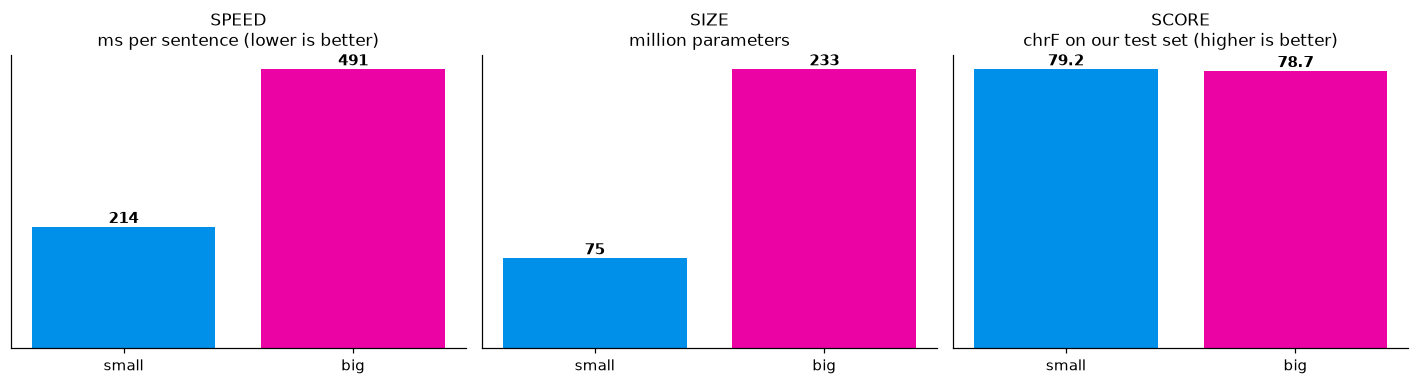

In [15]:
scores, timing = {}, {}
for name in MODELS:
    t0 = time.perf_counter()
    test[name] = translate(test["french"].tolist(), name)
    timing[name] = (time.perf_counter() - t0) * 1000 / len(test)
    refs = [test["reference"].tolist()]
    scores[name] = {"BLEU": sacrebleu.corpus_bleu(test[name].tolist(), refs).score,
                    "chrF": sacrebleu.corpus_chrf(test[name].tolist(), refs).score,
                    "TER (lower = better)": sacrebleu.corpus_ter(test[name].tolist(), refs).score}
    test[f"chrF {name}"] = [sacrebleu.sentence_chrf(h, [r]).score for h, r in zip(test[name], test["reference"])]

display(pd.DataFrame(scores).style.format("{:.1f}"))

names = list(MODELS)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (vals, title, fmt) in zip(axes, [([timing[n] for n in names], "SPEED\nms per sentence (lower is better)", "%.0f"),
                                         ([PARAMS[n] for n in names], "SIZE\nmillion parameters", "%.0f"),
                                         ([scores[n]["chrF"] for n in names], "SCORE\nchrF on our test set (higher is better)", "%.1f")]):
    bars = ax.bar(names, vals, color=[BLUE, PINK][:len(names)]); ax.bar_label(bars, fmt=fmt, fontweight="bold")
    ax.set_title(title, fontsize=11); ax.set_yticks([])
plt.tight_layout(); plt.show()

### Which kind of sentence is the hardest?

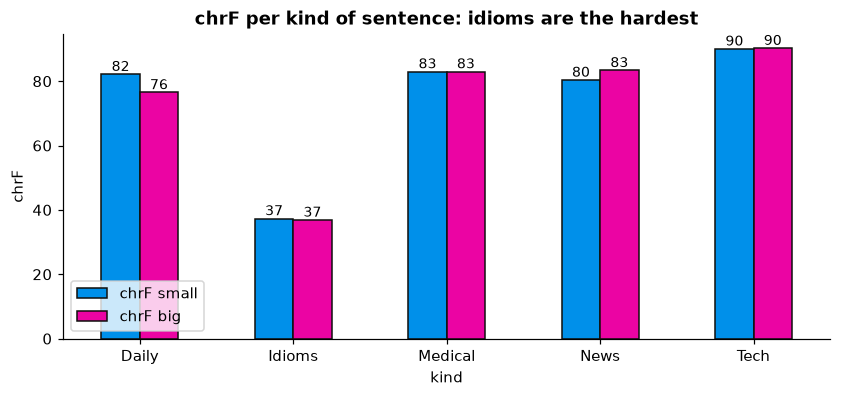

In [16]:
per_kind = test.groupby("kind")[[f"chrF {n}" for n in names]].mean()
ax = per_kind.plot.bar(figsize=(9, 3.6), color=[BLUE, PINK][:len(names)], rot=0, edgecolor="#100f0d")
for c_ in ax.containers: ax.bar_label(c_, fmt="%.0f", fontsize=9)
ax.set_title("chrF per kind of sentence: idioms are the hardest", fontweight="bold"); ax.set_ylabel("chrF"); plt.show()

worst = test.sort_values(f"chrF {names[-1]}").head(5)
display(HTML("<h4 style='font-family:sans-serif'>The 5 hardest sentences (green = words found in the reference)</h4>"
             + "".join(f"<div style='font-family:sans-serif;margin:6px 0;border-left:5px solid {PINK};padding-left:10px'>"
                       f"🇫🇷 {r.french}<br>🇬🇧 {color_match(r[names[-1]], r.reference)} <b>chrF {r[f'chrF {names[-1]}']:.0f}</b>"
                       f"<br><span style='color:#666;font-size:13px'>Reference: {r.reference}</span></div>" for _, r in worst.iterrows())))

## Step 11: The dangerous trap — BLEU prefers the wrong meaning

French: *"Le patient n'a pas de fièvre."* Reference: *"The patient does not have a fever."*
Two candidate translations: one is **correct**, the other says the **opposite**.

In [17]:
ref = "The patient does not have a fever."
candidates = {"✅ correct: The patient has no fever.": "The patient has no fever.",
              "❌ opposite: The patient does have a fever.": "The patient does have a fever."}
rows = []
for label, h in candidates.items():
    rows.append({"translation": label, "BLEU ↑": sacrebleu.sentence_bleu(h, [ref]).score,
                 "chrF ↑": sacrebleu.sentence_chrf(h, [ref]).score, "TER ↓": sacrebleu.sentence_ter(h, [ref]).score})
display(pd.DataFrame(rows).style.format({"BLEU ↑": "{:.1f}", "chrF ↑": "{:.1f}", "TER ↓": "{:.1f}"}).hide(axis="index"))
for label, h in candidates.items():
    display(HTML(f"<div style='font-family:sans-serif'>{label.split(':')[0]} {color_match(h, ref)}</div>"))

print("\nAll three metrics prefer the dangerous translation, because it shares more words with the reference.")
print("A tiny targeted test catches it. Does each model keep the negation?")
for name in MODELS:
    out = translate("Le patient n'a pas de fièvre.", name)
    keeps = bool(re.search(r"\b(no|not|n't|without)\b", out.lower()))
    print(f"   {name:>5}: {out:45s} -> negation kept: {'yes ✅' if keeps else 'NO ❌'}")

translation,BLEU ↑,chrF ↑,TER ↓
✅ correct: The patient has no fever.,16.4,52.0,57.1
❌ opposite: The patient does have a fever.,51.5,79.8,14.3


[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



All three metrics prefer the dangerous translation, because it shares more words with the reference.
A tiny targeted test catches it. Does each model keep the negation?


[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


   small: The patient has no fever.                     -> negation kept: yes ✅
     big: The patient has no fever.                     -> negation kept: yes ✅


## Step 12: One reference or three? Paraphrases are punished

*"Le chat dort sur le canapé"* has many correct translations. With **one** reference, BLEU punishes every other good choice.
With **several** references, the score becomes fairer.

[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


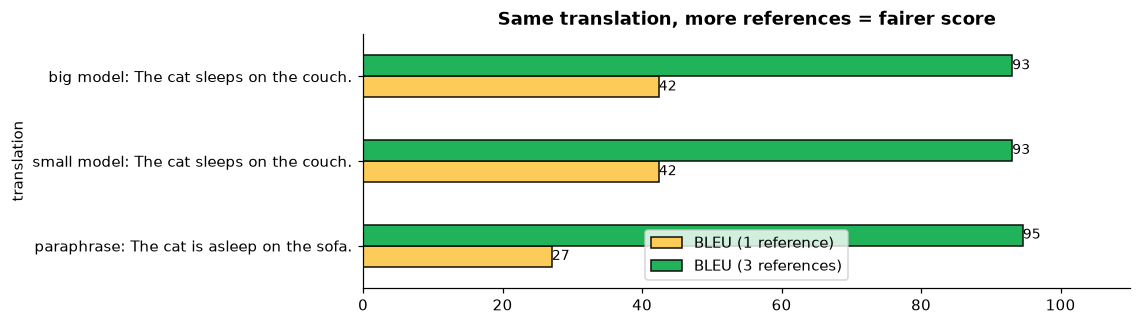

In [18]:
refs3 = ["The cat is sleeping on the couch.", "The cat sleeps on the sofa.", "The cat is asleep on the couch."]
hyps = {"paraphrase": "The cat is asleep on the sofa.", **{f"{n} model": translate("Le chat dort sur le canapé.", n) for n in MODELS}}
rows = [{"translation": f"{k}: {h}", "BLEU (1 reference)": sacrebleu.sentence_bleu(h, refs3[:1]).score,
         "BLEU (3 references)": sacrebleu.sentence_bleu(h, refs3).score} for k, h in hyps.items()]
df = pd.DataFrame(rows).set_index("translation")
ax = df.plot.barh(figsize=(9, 3), color=[YELLOW, GREEN], edgecolor="#100f0d", xlim=(0, 110))
for c_ in ax.containers: ax.bar_label(c_, fmt="%.0f", fontsize=9)
ax.set_title("Same translation, more references = fairer score", fontweight="bold"); plt.show()

## Step 13: Sentence score vs test-set score

BLEU on **one** sentence jumps a lot. BLEU on the **whole test set** is stable. Always report the corpus score.

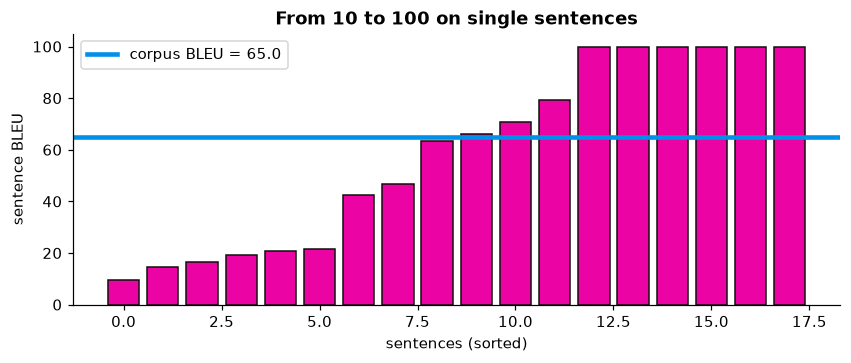

In [19]:
name = names[-1]
sent_bleu = [sacrebleu.sentence_bleu(h, [r]).score for h, r in zip(test[name], test["reference"])]
corpus = scores[name]["BLEU"]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(range(len(sent_bleu)), sorted(sent_bleu), color=PINK, edgecolor="#100f0d")
ax.axhline(corpus, color=BLUE, lw=3, label=f"corpus BLEU = {corpus:.1f}")
ax.set_xlabel("sentences (sorted)"); ax.set_ylabel("sentence BLEU"); ax.legend()
ax.set_title(f"From {min(sent_bleu):.0f} to {max(sent_bleu):.0f} on single sentences", fontweight="bold"); plt.show()

## Step 14 (optional): COMET, a neural metric

COMET reads the **source**, the **translation** and the **reference** with a neural network trained to imitate human scores.
It is closer to human judgment, but it is a heavy **black box**. Set `USE_COMET = True` to try it (2.3 GB download).

In [20]:
if USE_COMET:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "unbabel-comet"], check=True)
    from comet import download_model, load_from_checkpoint
    comet = load_from_checkpoint(download_model("Unbabel/wmt22-comet-da"))
    for name in MODELS:
        data = [{"src": s, "mt": m, "ref": r} for s, m, r in zip(test["french"], test[name], test["reference"])]
        print(f"{name}: COMET = {comet.predict(data, batch_size=8, gpus=0).system_score:.3f}")
    trap = [{"src": "Le patient n'a pas de fièvre.", "mt": h, "ref": "The patient does not have a fever."} for h in candidates.values()]
    print("Patient trap (correct, opposite):", [round(s, 3) for s in comet.predict(trap, batch_size=2, gpus=0).scores])
else:
    print("COMET skipped (USE_COMET = False).")

COMET skipped (USE_COMET = False).


## Step 15: Ethics test — does the model change women into men?

English often hides the gender of a job (*doctor*, *engineer*). French does not (*le médecin* / *la médecin*, *ingénieur* / *ingénieure*).
The pronoun (*she*, *he*) tells the gender. A fair model must follow the pronoun, **not the stereotype** (WinoMT test, Stanovsky et al., 2019).

In [23]:
en_fr = Translator(EN_FR_MODEL)

JOBS = {  # job: (feminine pattern, masculine pattern) in French
    "doctor":    (r"\b(la|une) (médecin|docteure?|doctoresse)\b", r"\b(le|un) (médecin|docteur)\b"),
    "engineer":  (r"\bingénieure\b", r"\bingénieur\b"),
    "nurse":     (r"\binfirmière\b", r"\binfirmier\b"),
    "mechanic":  (r"\bmécanicienne\b", r"\bmécanicien\b"),
    "developer": (r"\bdéveloppeuse\b", r"\bdéveloppeur\b"),
}
SENTENCES = [en_fr = pipeline("translation", model=EN_FR_MODEL)

    ("The doctor said that she was tired.", "doctor", "F"),
    ("The doctor said that he was tired.", "doctor", "M"),
    ("The engineer finished her report.", "engineer", "F"),
    ("The engineer finished his report.", "engineer", "M"),
    ("The nurse said that he was ready.", "nurse", "M"),
    ("The nurse said that she was ready.", "nurse", "F"),
    ("The mechanic fixed my car and she was very kind.", "mechanic", "F"),
    ("The developer explained her code.", "developer", "F"),
]
rows = []
for en, job, expected in SENTENCES:
    fr = en_fr(en, num_beams=NUM_BEAMS)[0]["translation_text"]
    fem, masc = JOBS[job]
    got = "F" if re.search(fem, fr.lower()) else ("M" if re.search(masc, fr.lower()) else "?")
    rows.append({"English": en, "French": fr, "expected": expected, "model": got,
                 "correct": "✅" if got == expected else ("❓" if got == "?" else "❌")})
gender = pd.DataFrame(rows)
display(gender.style.hide(axis="index"))
for g, label in [("F", "feminine"), ("M", "masculine")]:
    sub = gender[gender.expected == g]
    print(f"Correct gender when the person is {label}: {(sub.model == g).mean():.0%} ({len(sub)} sentences)")
print("If the score is much lower for women, the model follows the stereotype instead of the pronoun.")

Loading weights: 100%|██████████| 258/258 [00:00<00:00, 16221.90it/s]
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please

English,French,expected,model,correct
The doctor said that she was tired.,Le docteur a dit qu'elle était fatiguée.,F,M,❌
The doctor said that he was tired.,Le docteur a dit qu'il était fatigué.,M,M,✅
The engineer finished her report.,L'ingénieur a terminé son rapport.,F,M,❌
The engineer finished his report.,L'ingénieur a terminé son rapport.,M,M,✅
The nurse said that he was ready.,L'infirmière a dit qu'il était prêt.,M,F,❌
The nurse said that she was ready.,L'infirmière a dit qu'elle était prête.,F,F,✅
The mechanic fixed my car and she was very kind.,Le mécanicien a réparé ma voiture et elle était très gentille.,F,M,❌
The developer explained her code.,Le développeur a expliqué son code.,F,M,❌


Correct gender when the person is feminine: 20% (5 sentences)
Correct gender when the person is masculine: 67% (3 sentences)
If the score is much lower for women, the model follows the stereotype instead of the pronoun.


## Step 16: Three numbers to remember

| | Question | Metric | Trap |
|---|---|---|---|
| **BLEU** | How many groups of words are shared with the reference? | n-gram precision × brevity penalty | Punishes good paraphrases, rewards a wrong meaning with the same words |
| **chrF / TER** | Same idea with letters / number of edits | F-score on characters / edits ÷ length | Still counts surface, not meaning |
| **Human / COMET** | Is the meaning correct and natural? | human scores / neural metric | Expensive / black box |

**Good practice for a serious evaluation**
- Report the **corpus** score, never one sentence.
- Use **several references** when possible.
- Combine a **surface metric** (BLEU, chrF) and a **neural one** (COMET).
- Add **targeted tests** for what matters: negation, numbers, names, gender.
- Ask **humans** to check the risky sentences (medicine, law).

### Things to try
- Set `NUM_BEAMS = 1` (greedy): faster, but does the score drop?
- Add your own sentences to `TEST`, for example in your field of study.
- Translate the English output back into French with `en_fr`: does it come back the same? (*back-translation*)

### Common problems
| Problem | Solution |
|---|---|
| `sentencepiece` or `sacremoses` error | `pip install sentencepiece sacremoses`, then restart the kernel |
| The big model is too slow | `RUN_BIG_MODEL = False` |
| Scores differ from a friend's | Same models and same `NUM_BEAMS`? sacreBLEU makes the scoring itself identical |